# ALIGN retriever

## Data Preperation

We will do the same data preperation that we did for the CLIP model

In [1]:
import pandas as pd
import os
from PIL import Image

In [2]:
csv_path = "posters/MovieGenre.csv"
image_dir = "posters/SampleMoviePosters/SampleMoviePosters/"

df = pd.read_csv(csv_path, encoding='latin-1')
print(f"A total of {len(df)} entries.")

df = df.dropna(subset=['imdbId', 'Title', 'Genre'])
print(f"After droping NA we have a total of {len(df)} entries.")

A total of 40108 entries.
After droping NA we have a total of 39963 entries.


In [3]:
df = df.drop_duplicates(subset=['imdbId'])
print(f"After removing duplicate imdbIds we have a total of {len(df)} entries.")

After removing duplicate imdbIds we have a total of 39370 entries.


In [4]:
images = []
titles = []
movie_genres = []

for index, row in df.iterrows():
    # In the standard IMDB poster dataset, images are named "{imdbId}.jpg"
    imdb_id = row['imdbId'] 
    img_path = os.path.join(image_dir, f"{imdb_id}.jpg")
    
    if os.path.exists(img_path):
        try:
            img = Image.open(img_path)
            images.append(img)
            
            titles.append(row['Title'])
            
            # Split the "Action|Adventure|Sci-Fi" string into a list
            g_list = [g.strip() for g in row['Genre'].split('|')]
            movie_genres.append(g_list)
            
                
        except Exception as e:
            print(f"Skipping corrupted/unreadable image {img_path}: {e}")
    else:
        print(f"Image {img_path} does not exist.")

Image posters/SampleMoviePosters/SampleMoviePosters/114709.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113497.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113228.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/114885.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113041.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113277.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/114319.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/112302.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/114576.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113189.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/112346.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/112896.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/

In [5]:
print(f"Successfully loaded {len(images)} posters")
print(f"Length of titles is {len(titles)}")
print(f"Length of genres is {len(movie_genres)}")

Successfully loaded 997 posters
Length of titles is 997
Length of genres is 997


In [6]:
# Flatten the list of lists and then convert to a set
unique_genres = set([genre for sublist in movie_genres for genre in sublist])
unique_genres = list(unique_genres)
print(f"A total of {len(unique_genres)} genres.")
print(unique_genres)

A total of 23 genres.
['Fantasy', 'Family', 'Action', 'Horror', 'Short', 'Music', 'Romance', 'History', 'Sport', 'Mystery', 'Western', 'Musical', 'War', 'Drama', 'Thriller', 'Comedy', 'Adventure', 'Animation', 'Film-Noir', 'Documentary', 'Biography', 'Crime', 'Sci-Fi']


## Retrieval

In [7]:
from transformers import AlignProcessor, AlignModel
import torch

/home/beauty/Multimodal-CLIP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
align_processor = AlignProcessor.from_pretrained("kakaobrain/align-base")
align_model = AlignModel.from_pretrained("kakaobrain/align-base").to(device)


Loading weights: 100%|██████████| 1394/1394 [00:00<00:00, 35318.85it/s]


The ALIGN model runs out of memory when trying to encode the images, so we need to implement batching.

In [17]:
batch_size = 64
image_features_list = []
title_features_list = []

with torch.no_grad():
    for i in range(0, len(images), batch_size):
        batch_imgs = images[i: i + batch_size]
        batch_titles = titles[i: i + batch_size]

        # the ALIGN model handles lists of images, so no need to use torch.stack
        # It also handles text and images at the same time
        inputs = align_processor(text=batch_titles,
                                       images=batch_imgs, 
                                       return_tensors='pt',
                                       padding=True).to(device)
        outputs = align_model(**inputs)
        image_features = outputs.image_embeds
        text_features = outputs.text_embeds

        image_features /= image_features.norm(dim=-1, keepdim=True)
        text_features /= text_features.norm(dim=-1, keepdim=True)

        image_features_list.append(image_features)
        title_features_list.append(text_features)

image_features = torch.cat(image_features_list, dim=0)
title_features = torch.cat(title_features_list, dim=0)



/home/beauty/Multimodal-CLIP/.venv/lib/python3.14/site-packages/transformers/tokenization_utils_base.py:2386: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


In [24]:
def retrieve_posters_by_genre(target_genre, top_k=3, prompt=None):
    if prompt is None:
        prompt = f"A movie poster for a {target_genre} movie."

    # ALIGN needs both an image and a text to function
    # so in order to run the model we will use a dummy image
    dummy_img = images[0]

    inputs = align_processor(
        text=[prompt], 
        images=dummy_img, 
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = align_model(**inputs)
        text_features = outputs.text_embeds
        text_features /= text_features.norm(dim=-1, keepdim=True)

    similarities = (text_features @ image_features.T).squeeze(0)
    top_indices = similarities.topk(top_k).indices.tolist()

    return [images[i] for i in top_indices]

In [31]:
def classify_poster_genre(image_idx, top_k=3, prompt_template="A movie poster for a {} movie."):
    prompts = [prompt_template.format(g) for g in unique_genres]

    inputs = align_processor(
        text=prompts,
        images = [images[image_idx]]*len(prompts),
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = align_model(**inputs)
        text_features = outputs.text_embeds
        text_features /= text_features.norm(dim=-1, keepdim=True)

    target_image_feature = image_features[image_idx].unsqueeze(0).float()
    text_probs = (100.0 * target_image_feature @ text_features.T).softmax(dim=-1)

    top_probs, top_indices = text_probs.cpu().topk(top_k, dim=-1)
    
    top_probs = top_probs.squeeze(0).tolist()
    top_indices = top_indices.squeeze(0).tolist()
    
    results = []
    
    for prob, idx in zip(top_probs, top_indices):
        genre = unique_genres[idx]
        results.append((genre, prob))
        
    return results




In [33]:
def retrieve_poster_by_title(target_title, top_k=3, prompt_template="A movie poster for the film {}."):
    prompt = prompt_template.format(target_title)
    
    # Process the text prompt alongside a dummy image to bypass the bug
    inputs = align_processor(
        text=[prompt],
        images=[images[0]], 
        return_tensors="pt"
    ).to(device)
    
    with torch.no_grad():
        outputs = align_model(**inputs)
        text_features = outputs.text_embeds
        text_features /= text_features.norm(dim=-1, keepdim=True)
    
    probs = (100.0 * text_features.float() @ image_features.float().T).softmax(dim=-1).squeeze(0)
    top_probs, top_indices = probs.cpu().topk(top_k, dim=-1)

    top_probs = top_probs.tolist()
    top_indices = top_indices.tolist()

    results = []

    for (prob, i) in zip(top_probs, top_indices):
        retrieved_title = titles[i]
        retrieved_image = images[i]
        results.append((retrieved_image, prob, retrieved_title))
    
    return results

In [39]:
def retrieve_title_by_poster(image_idx, prompt_template="A movie poster for the film {}.", top_k=3):

    target_image_feature = image_features[image_idx].unsqueeze(0).float()

    prompts = [prompt_template.format(t) for t in titles]

    # batching to prevent OOM errors
    batch_size = 64
    text_features_list = []

    for i in range(0, len(prompts), batch_size):
        batch_prompts = prompts[i: i + batch_size]
        imgs = [images[image_idx]]*len(batch_prompts)

        inputs = align_processor(
            text = batch_prompts,
            images = imgs,
            return_tensors="pt",
            padding=True
        ).to(device)

        with torch.no_grad():
            outputs = align_model(**inputs)
            text_features = outputs.text_embeds
            text_features /= text_features.norm(dim=-1, keepdim=True)
            text_features_list.append(text_features)

    text_features = torch.cat(text_features_list, dim=0)

    text_probs = (100.0 * target_image_feature @ text_features.T).softmax(dim=-1)
    
    top_probs, top_indices = text_probs.cpu().topk(top_k, dim=-1)
    top_probs = top_probs.squeeze(0).tolist()
    top_indices = top_indices.squeeze(0).tolist()
    
    results = []
    for rank, (prob, idx) in enumerate(zip(top_probs, top_indices), 1):
        predicted_title = titles[idx]
        results.append((predicted_title, prob))
        
    return results

Let us now test the code on the same examples we evaluated CLIP on

In [41]:
import matplotlib.pyplot as plt
import numpy as np

In [42]:
posters = retrieve_posters_by_genre("Horror")

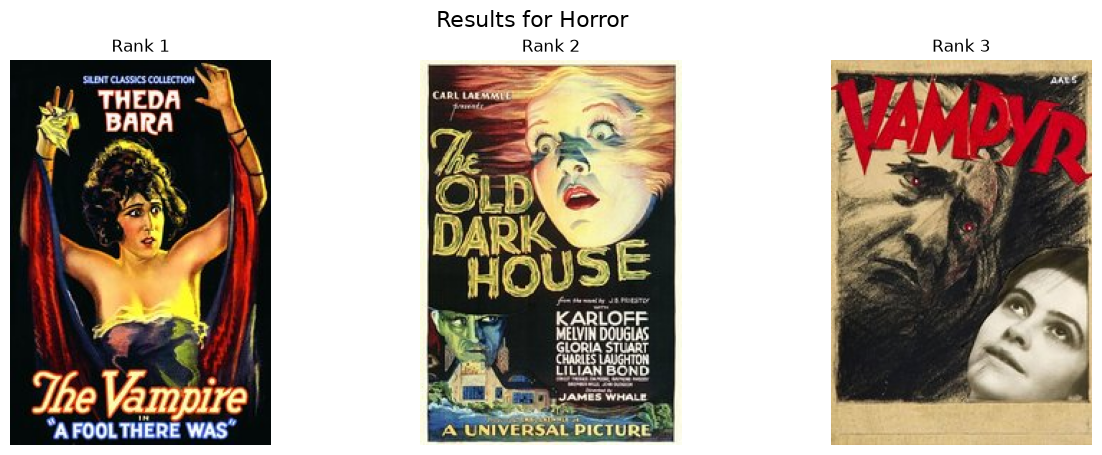

In [43]:
fig, axes = plt.subplots(1,3,figsize=(15,5))
for i, img in enumerate(posters):
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Rank {i+1}")
plt.suptitle("Results for Horror", fontsize=16)
plt.show()

The results look similar to those of CLIP

In [44]:
predicted_genres = classify_poster_genre(3)

/home/beauty/Multimodal-CLIP/.venv/lib/python3.14/site-packages/transformers/tokenization_utils_base.py:2386: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


In [45]:
predicted_genres

[('Mystery', 0.32042253017425537),
 ('Film-Noir', 0.18010005354881287),
 ('Horror', 0.10559502243995667)]

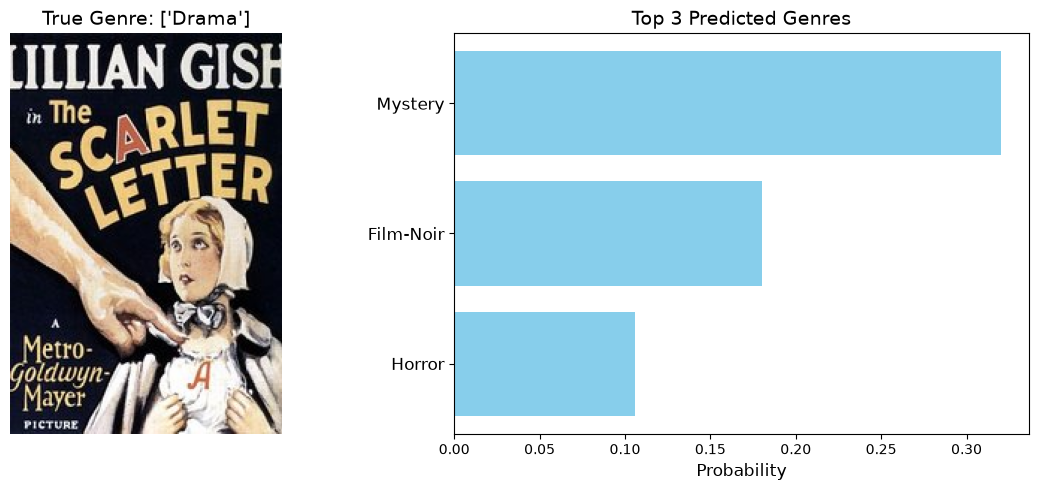

In [46]:
img = images[3]
true_genre = movie_genres[3]

pred_genres = [pred[0] for pred in predicted_genres]
pred_probs = [pred[1] for pred in predicted_genres]

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title(f"True Genre: {true_genre}", fontsize=14)
plt.axis("off")

plt.subplot(1,2,2)
y = np.arange(len(predicted_genres))
plt.barh(y, pred_probs, color="skyblue")

# Invert y-axis so the #1 highest probability is at the very top of the chart
plt.gca().invert_yaxis()

plt.yticks(y, pred_genres, fontsize=12)
plt.xlabel("Probability", fontsize=12)
plt.title("Top 3 Predicted Genres", fontsize=14)

plt.tight_layout()
plt.show()

The results are equally disappointing as they were with CLIP.

In [47]:
predicted_posters = retrieve_poster_by_title("Today we live")

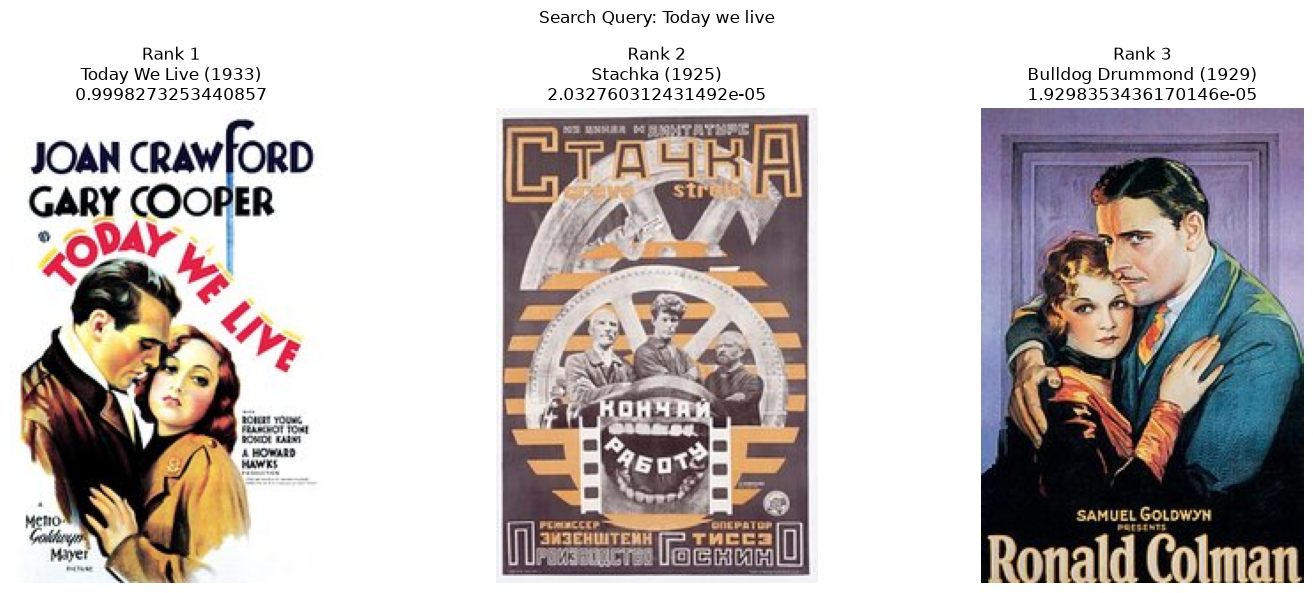

In [48]:
fig, axes = plt.subplots(1, len(predicted_posters), figsize=(15,6))
for i, (img,prob,title) in enumerate(predicted_posters):
    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(f"Rank {i+1}\n{title}\n{prob}", fontsize=12)
plt.suptitle("Search Query: Today we live")
plt.tight_layout()
plt.show()

The results are similar to those of CLIP (with a slightly higher confidence in returning the correct result).

In [49]:
predicted_titles = retrieve_title_by_poster(3)

/home/beauty/Multimodal-CLIP/.venv/lib/python3.14/site-packages/transformers/tokenization_utils_base.py:2386: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


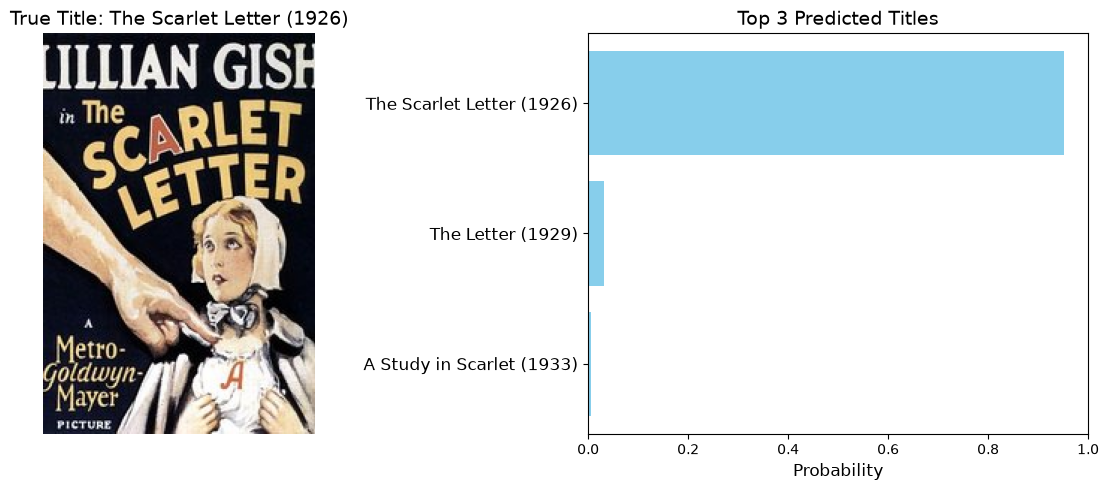

In [50]:
img = images[3]
true_title = titles[3]

pred_titles = [pred[0] for pred in predicted_titles]
pred_probs = [pred[1] for pred in predicted_titles]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(f"True Title: {true_title}", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
y = np.arange(len(pred_titles))

plt.barh(y, pred_probs, color='skyblue')

# Invert y-axis so the #1 highest probability is at the top
plt.gca().invert_yaxis()

plt.yticks(y, pred_titles, fontsize=12)
plt.xlabel("Probability", fontsize=12)
plt.title("Top 3 Predicted Titles", fontsize=14)

plt.tight_layout()
plt.show()

Amazing! The ALIGN model worked much better than CLIP! Not only did it return the correct title but it is also very confident.